# Binary Classification - Deep Learning & Neural Networks

#### Step 1 - Import required libraries

In [8]:
import pandas as pd

from tensorflow import keras
from tensorflow.keras import layers, callbacks

from IPython.display import display

#### Step 2 - Load Data

In [2]:
ion_data = pd.read_csv("../resources/ion.csv", index_col=0)
display(ion_data.head())

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V26,V27,V28,V29,V30,V31,V32,V33,V34,Class
1,1,0,0.99539,-0.05889,0.85243,0.02306,0.83398,-0.37708,1.00000,0.03760,...,-0.51171,0.41078,-0.46168,0.21266,-0.34090,0.42267,-0.54487,0.18641,-0.45300,good
2,1,0,1.00000,-0.18829,0.93035,-0.36156,-0.10868,-0.93597,1.00000,-0.04549,...,-0.26569,-0.20468,-0.18401,-0.19040,-0.11593,-0.16626,-0.06288,-0.13738,-0.02447,bad
3,1,0,1.00000,-0.03365,1.00000,0.00485,1.00000,-0.12062,0.88965,0.01198,...,-0.40220,0.58984,-0.22145,0.43100,-0.17365,0.60436,-0.24180,0.56045,-0.38238,good
4,1,0,1.00000,-0.45161,1.00000,1.00000,0.71216,-1.00000,0.00000,0.00000,...,0.90695,0.51613,1.00000,1.00000,-0.20099,0.25682,1.00000,-0.32382,1.00000,bad
5,1,0,1.00000,-0.02401,0.94140,0.06531,0.92106,-0.23255,0.77152,-0.16399,...,-0.65158,0.13290,-0.53206,0.02431,-0.62197,-0.05707,-0.59573,-0.04608,-0.65697,good


#### Step 3 - Prepare Data

1. Target Column : 'Class' - [good, bad] => [0,1]
2. Data split - 70% train | 30% validation

In [3]:
df = ion_data.copy()
df['Class'] = df['Class'].map(
    {
        'good': 1,
        'bad': 0
    }
)
display(df.head())

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V26,V27,V28,V29,V30,V31,V32,V33,V34,Class
1,1,0,0.99539,-0.05889,0.85243,0.02306,0.83398,-0.37708,1.00000,0.03760,...,-0.51171,0.41078,-0.46168,0.21266,-0.34090,0.42267,-0.54487,0.18641,-0.45300,1
2,1,0,1.00000,-0.18829,0.93035,-0.36156,-0.10868,-0.93597,1.00000,-0.04549,...,-0.26569,-0.20468,-0.18401,-0.19040,-0.11593,-0.16626,-0.06288,-0.13738,-0.02447,0
3,1,0,1.00000,-0.03365,1.00000,0.00485,1.00000,-0.12062,0.88965,0.01198,...,-0.40220,0.58984,-0.22145,0.43100,-0.17365,0.60436,-0.24180,0.56045,-0.38238,1
4,1,0,1.00000,-0.45161,1.00000,1.00000,0.71216,-1.00000,0.00000,0.00000,...,0.90695,0.51613,1.00000,1.00000,-0.20099,0.25682,1.00000,-0.32382,1.00000,0
5,1,0,1.00000,-0.02401,0.94140,0.06531,0.92106,-0.23255,0.77152,-0.16399,...,-0.65158,0.13290,-0.53206,0.02431,-0.62197,-0.05707,-0.59573,-0.04608,-0.65697,1


Split the dataset

In [4]:
df_train = df.sample(frac=0.7, random_state=0)
df_valid = df.drop(df_train.index)
print(f"Train Dataset Index: {df_train.index}")

Train Dataset Index: Index([  7,  53, 115,  46, 107, 259, 187, 230, 214,  90,
       ...
       261,  87,  11,  37, 335,  59,  42,  15, 156,  51],
      dtype='int64', length=246)


In [5]:
max_ = df_train.max(axis=0)
min_ = df_train.min(axis=0)

df_train = (df_train - min_) / (max_ - min_)
df_valid = (df_valid - min_) / (max_ - min_)
df_train.dropna(axis=1, inplace=True) # drop the empty feature in column 2
df_valid.dropna(axis=1, inplace=True)

X_train = df_train.drop('Class', axis=1)
X_valid = df_valid.drop('Class', axis=1)
y_train = df_train['Class']
y_valid = df_valid['Class']

#### Step 4 - Define Model

In [6]:
model = keras.Sequential(
    [
        layers.Input(shape=(X_train.shape[1],)),
        layers.Dense(4, activation='relu'),
        layers.Dense(4, activation='relu'),
        layers.Dense(1, activation='sigmoid')
    ]
)

2026-10-10 14:47:23.232331: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M5
2026-10-10 14:47:23.232434: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 32.00 GB
2026-10-10 14:47:23.232444: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 12.48 GB
I0000 00:00:1791604043.232461 16774658 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1791604043.232498 16774658 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [7]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['binary_accuracy']
)

In [9]:
early_stopping = callbacks.EarlyStopping(
    min_delta = 0.001,
    patience = 10,
    restore_best_weights = True
)

In [10]:
history = model.fit(
    X_train, y_train,
    validation_data = (X_valid, y_valid),
    batch_size = 512,
    epochs = 1000,
    callbacks = [early_stopping]
)

Epoch 1/1000


2026-10-10 14:49:41.836656: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - binary_accuracy: 0.4837 - loss: 0.7418 - val_binary_accuracy: 0.3714 - val_loss: 0.7520
Epoch 2/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - binary_accuracy: 0.4675 - loss: 0.7357 - val_binary_accuracy: 0.3714 - val_loss: 0.7411
Epoch 3/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - binary_accuracy: 0.4593 - loss: 0.7299 - val_binary_accuracy: 0.3810 - val_loss: 0.7307
Epoch 4/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - binary_accuracy: 0.4593 - loss: 0.7244 - val_binary_accuracy: 0.3905 - val_loss: 0.7206
Epoch 5/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - binary_accuracy: 0.4350 - loss: 0.7193 - val_binary_accuracy: 0.4095 - val_loss: 0.7110
Epoch 6/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - binary_accuracy: 0.4228 - loss: 0.7146 - val_binary_accuracy: 0.4000 - val_loss: 0.7019
Epoch 7/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - binary_accuracy: 0.4024 - loss: 0.7101 - val_binary_accuracy: 0.4476 - val_loss: 0.6931
Epoch 8/1000
1/1 ━━━━━━━━━━━

Best Validation Loss: 0.5657
Best Validation Accuracy: 0.7810


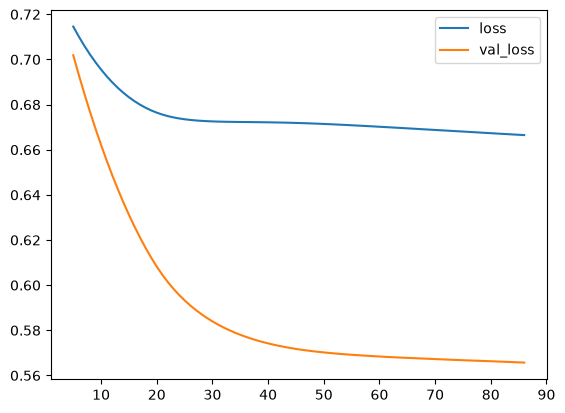

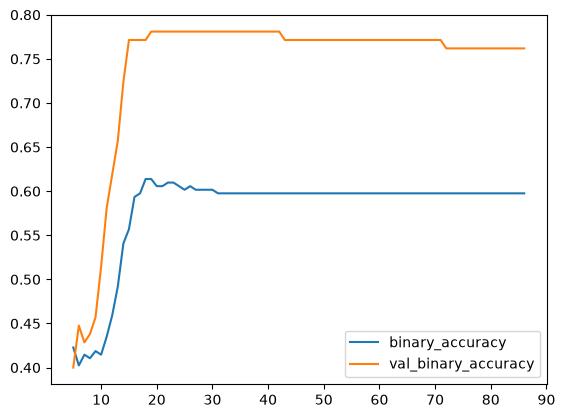

In [11]:
history_df = pd.DataFrame(history.history)

history_df.loc[5:, ['loss', 'val_loss']].plot()
history_df.loc[5:, ['binary_accuracy', 'val_binary_accuracy']].plot()

print(("Best Validation Loss: {:0.4f}" +\
      "\nBest Validation Accuracy: {:0.4f}")\
      .format(history_df['val_loss'].min(),
              history_df['val_binary_accuracy'].max()))